<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/04_gravitational_lensing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import sys

repo_path = "/content/Blackhole_simulator_rayTracing"

if not os.path.exists(repo_path):
    %cd /content
    !git clone https://github.com/AnshG-19/Blackhole_simulator_rayTracing.git

os.chdir(repo_path)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

print("Repository connected:", os.getcwd())

/content
Cloning into 'Blackhole_simulator_rayTracing'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 72 (delta 16), reused 17 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 1.34 MiB | 3.64 MiB/s, done.
Resolving deltas: 100% (16/16), done.
Repository connected: /content/Blackhole_simulator_rayTracing


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from src.physics.ray_tracing import calculate_light_ray

M = 1.0
b = 8.0

ray = calculate_light_ray(
    mass_parameter=M,
    impact_parameter=b,
    max_angle=4.0,
    points=1500,
)

print(f"Black hole mass parameter: {M:.1f} M")
print(f"Impact parameter: {b:.2f} M")
print(f"Closest approach: {ray['closest_approach']:.3f} M")
print(f"Critical impact parameter: {ray['critical_impact_parameter']:.3f} M")

Black hole mass parameter: 1.0 M
Impact parameter: 8.00 M
Closest approach: 6.701 M
Critical impact parameter: 5.196 M


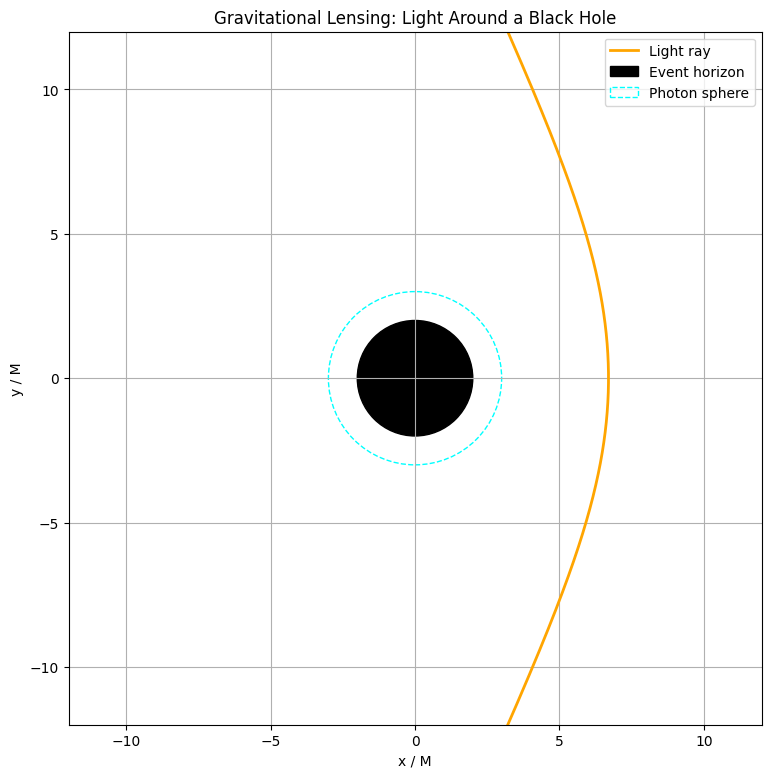

In [3]:
fig, ax = plt.subplots(figsize=(9, 9))

ax.plot(ray["x"], ray["y"], color="orange", linewidth=2, label="Light ray")
ax.add_patch(plt.Circle((0, 0), 2 * M, color="black", label="Event horizon"))
ax.add_patch(
    plt.Circle(
        (0, 0),
        3 * M,
        fill=False,
        linestyle="--",
        color="cyan",
        label="Photon sphere",
    )
)

ax.set_xlim(-12, 12)
ax.set_ylim(-12, 12)
ax.set_aspect("equal")
ax.set_xlabel("x / M")
ax.set_ylabel("y / M")
ax.set_title("Gravitational Lensing: Light Around a Black Hole")
ax.grid(True)
ax.legend()

plt.show()

In [4]:
# Weak-field approximation for the deflection angle

alpha_weak = 4 * M / b

print("Gravitational Lensing — Deflection Check")
print("----------------------------------------")
print(f"Mass parameter M: {M:.2f}")
print(f"Impact parameter b: {b:.2f} M")
print(f"Weak-field deflection: {alpha_weak:.4f} radians")
print(f"Weak-field deflection: {np.degrees(alpha_weak):.2f} degrees")

Gravitational Lensing — Deflection Check
----------------------------------------
Mass parameter M: 1.00
Impact parameter b: 8.00 M
Weak-field deflection: 0.5000 radians
Weak-field deflection: 28.65 degrees


In [5]:
impact_parameters = [6.0, 7.0, 8.0, 10.0, 15.0, 20.0]

print(f"{'Impact b / M':<15}{'Weak angle (deg)':<20}")
print("-" * 35)

for b_value in impact_parameters:
    if b_value <= 3 * np.sqrt(3):
        print(f"{b_value:<15.1f}{'Captured threshold':<20}")
        continue

    alpha = 4 * M / b_value

    print(
        f"{b_value:<15.1f}"
        f"{np.degrees(alpha):<20.2f}"
    )

Impact b / M   Weak angle (deg)    
-----------------------------------
6.0            38.20               
7.0            32.74               
8.0            28.65               
10.0           22.92               
15.0           15.28               
20.0           11.46               


In [6]:
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
import numpy as np

def numerical_deflection(mass_parameter, impact_parameter):
    M = float(mass_parameter)
    b = float(impact_parameter)

    b_critical = 3 * np.sqrt(3) * M

    if M <= 0 or b <= b_critical:
        raise ValueError("Require M > 0 and b > 3*sqrt(3)*M.")

    def turning_equation(r):
        return r**3 - b**2 * r + 2 * M * b**2

    r_min = brentq(turning_equation, 3 * M, b)

    # Integrate u = 1/r from closest approach toward infinity.
    def orbit_equation(phi, state):
        u, du_dphi = state
        return [du_dphi, 3 * M * u**2 - u]

    def reach_radius(phi, state):
        return state[0] - 1e-8 / M

    reach_radius.terminal = True
    reach_radius.direction = -1

    solution = solve_ivp(
        orbit_equation,
        (0.0, np.pi),
        [1.0 / r_min, 0.0],
        events=reach_radius,
        rtol=1e-10,
        atol=1e-12,
        max_step=0.005,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    phi_infinity = solution.t[-1]

    # In flat spacetime, the half-orbit angle would be pi/2.
    return 2 * phi_infinity - np.pi

In [7]:
impact_parameters = [6.0, 7.0, 8.0, 10.0, 15.0, 20.0]

print(
    f"{'b / M':<10}"
    f"{'Numerical (deg)':<20}"
    f"{'Weak-field (deg)':<20}"
)
print("-" * 50)

for b_value in impact_parameters:
    numerical = numerical_deflection(M, b_value)
    weak_field = 4 * M / b_value

    print(
        f"{b_value:<10.1f}"
        f"{np.degrees(numerical):<20.2f}"
        f"{np.degrees(weak_field):<20.2f}"
    )

b / M     Numerical (deg)     Weak-field (deg)    
--------------------------------------------------
6.0       98.51               38.20               
7.0       64.61               32.74               
8.0       49.20               28.65               
10.0      33.83               22.92               
15.0      19.27               15.28               
20.0      13.53               11.46               


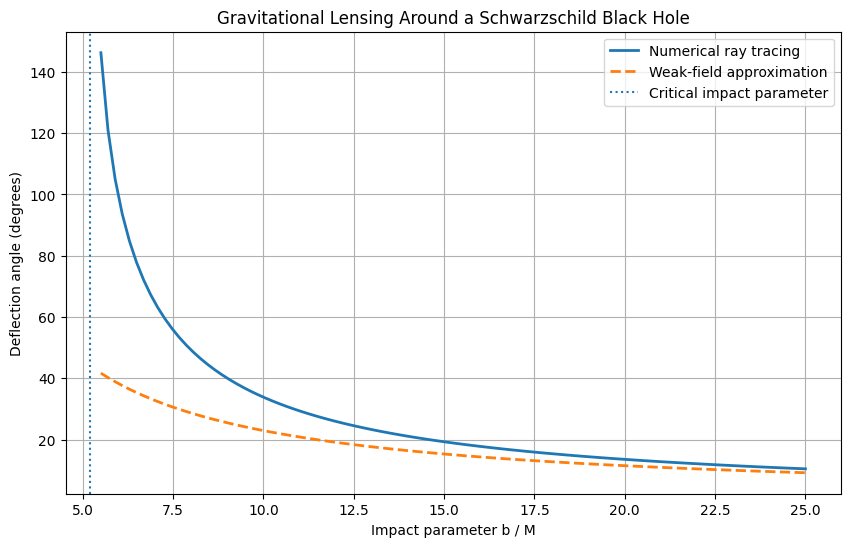

In [8]:
import matplotlib.pyplot as plt
import numpy as np

impact_parameters = np.linspace(5.5, 25.0, 100)

numerical_angles = []
weak_field_angles = []

for b_value in impact_parameters:
    numerical_angles.append(
        np.degrees(numerical_deflection(M, b_value))
    )

    weak_field_angles.append(
        np.degrees(4 * M / b_value)
    )

plt.figure(figsize=(10, 6))

plt.plot(
    impact_parameters,
    numerical_angles,
    label="Numerical ray tracing",
    linewidth=2,
)

plt.plot(
    impact_parameters,
    weak_field_angles,
    "--",
    label="Weak-field approximation",
    linewidth=2,
)

plt.axvline(
    3 * np.sqrt(3) * M,
    linestyle=":",
    label="Critical impact parameter",
)

plt.xlabel("Impact parameter b / M")
plt.ylabel("Deflection angle (degrees)")
plt.title("Gravitational Lensing Around a Schwarzschild Black Hole")
plt.grid(True)
plt.legend()
plt.show()

In [9]:
print("Weak-Field Limit Check")
print("-" * 55)
print(f"{'b / M':<10}{'Numerical (deg)':<20}{'Weak-field (deg)':<20}")

for b_value in [20.0, 30.0, 50.0, 100.0]:
    numerical = numerical_deflection(M, b_value)
    weak_field = 4 * M / b_value

    print(
        f"{b_value:<10.1f}"
        f"{np.degrees(numerical):<20.4f}"
        f"{np.degrees(weak_field):<20.4f}"
    )

Weak-Field Limit Check
-------------------------------------------------------
b / M     Numerical (deg)     Weak-field (deg)    
20.0      13.5296             11.4592             
30.0      8.4940              7.6394              
50.0      4.8749              4.5837              
100.0     2.3618              2.2918              



# Black Hole Simulator — Gravitational Lensing

## Objectives
- Create a synthetic background starfield
- Model light bending around a Schwarzschild black hole
- Build a simple lensing visualization
- Understand how ray tracing can produce a black hole shadow


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# print("Gravitational lensing notebook initialized.")

Gravitational lensing notebook initialized.


Step 3 — Define the lensing model
For this notebook, we'll start with the point-mass thin-lens approximation. This is a standard simplified gravitational-lensing model. It is easier to understand and visualize before we build a full relativistic renderer.

In [ ]:
# # Normalized lensing units
# theta_E = 1.2

# # Number of background stars
# number_of_stars = 250

# print("Einstein radius:", theta_E)
# print("Number of background stars:", number_of_stars)

Einstein radius: 1.2
Number of background stars: 250


Generate the background stars
Add another code cell:

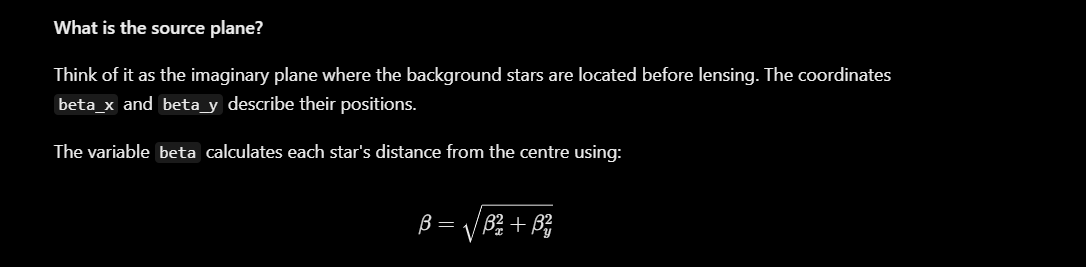

In [ ]:
# np.random.seed(42)

# # Background star coordinates in the source plane
# beta_x = np.random.uniform(-4, 4, number_of_stars)
# beta_y = np.random.uniform(-4, 4, number_of_stars)

# # Distance of each star from the optical axis
# beta = np.sqrt(beta_x**2 + beta_y**2)

# print("Generated stars:", len(beta_x))
# print("Minimum source distance:", beta.min())
# print("Maximum source distance:", beta.max())

Generated stars: 250
Minimum source distance: 0.3629652367805667
Maximum source distance: 5.431570204857783


Visualize the original starfield

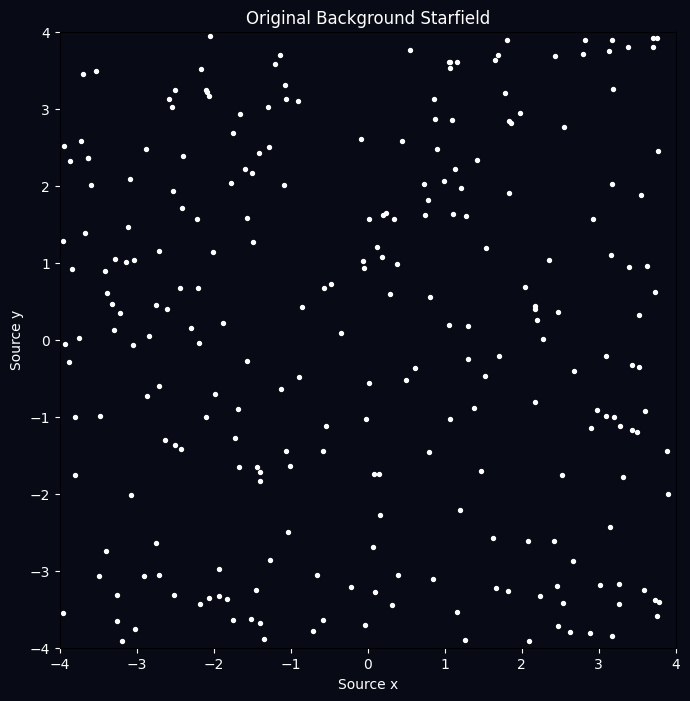

In [ ]:
# fig, ax = plt.subplots(figsize=(8, 8))

# ax.scatter(
#     beta_x,
#     beta_y,
#     s=8,
#     color="white"
# )

# ax.set_facecolor("#080b16")
# fig.patch.set_facecolor("#080b16")

# ax.set_xlim(-4, 4)
# ax.set_ylim(-4, 4)
# ax.set_aspect("equal")

# ax.set_title("Original Background Starfield", color="white")
# ax.set_xlabel("Source x", color="white")
# ax.set_ylabel("Source y", color="white")
# ax.tick_params(colors="white")

# plt.show()

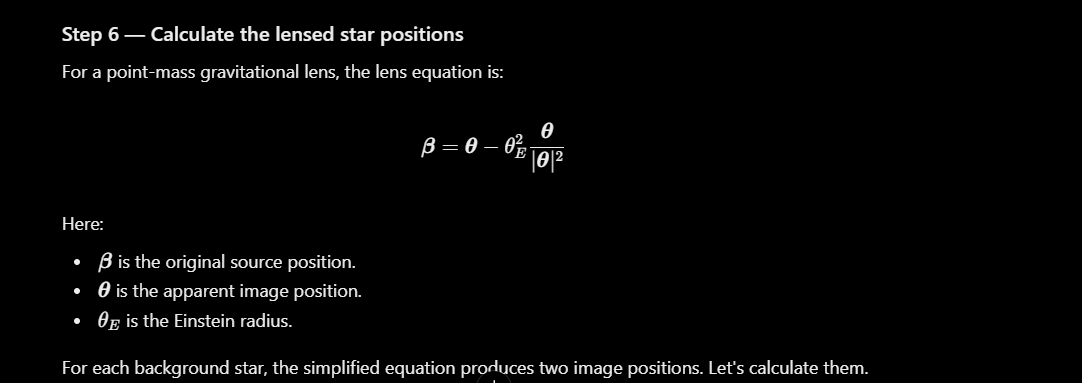

In [ ]:
# # Avoid division by zero for a star exactly at the centre
# safe_beta = np.maximum(beta, 1e-10)

# # Solve the point-mass lens equation
# root = np.sqrt(beta**2 + 4 * theta_E**2)

# theta_plus = (beta + root) / 2
# theta_minus = (beta - root) / 2

# # Convert radial image positions to x and y coordinates
# theta_plus_x = theta_plus * beta_x / safe_beta
# theta_plus_y = theta_plus * beta_y / safe_beta

# theta_minus_x = theta_minus * beta_x / safe_beta
# theta_minus_y = theta_minus * beta_y / safe_beta

# print("Calculated two image positions per source star.")

Calculated two image positions per source star.


#Plot the gravitational lensing effect

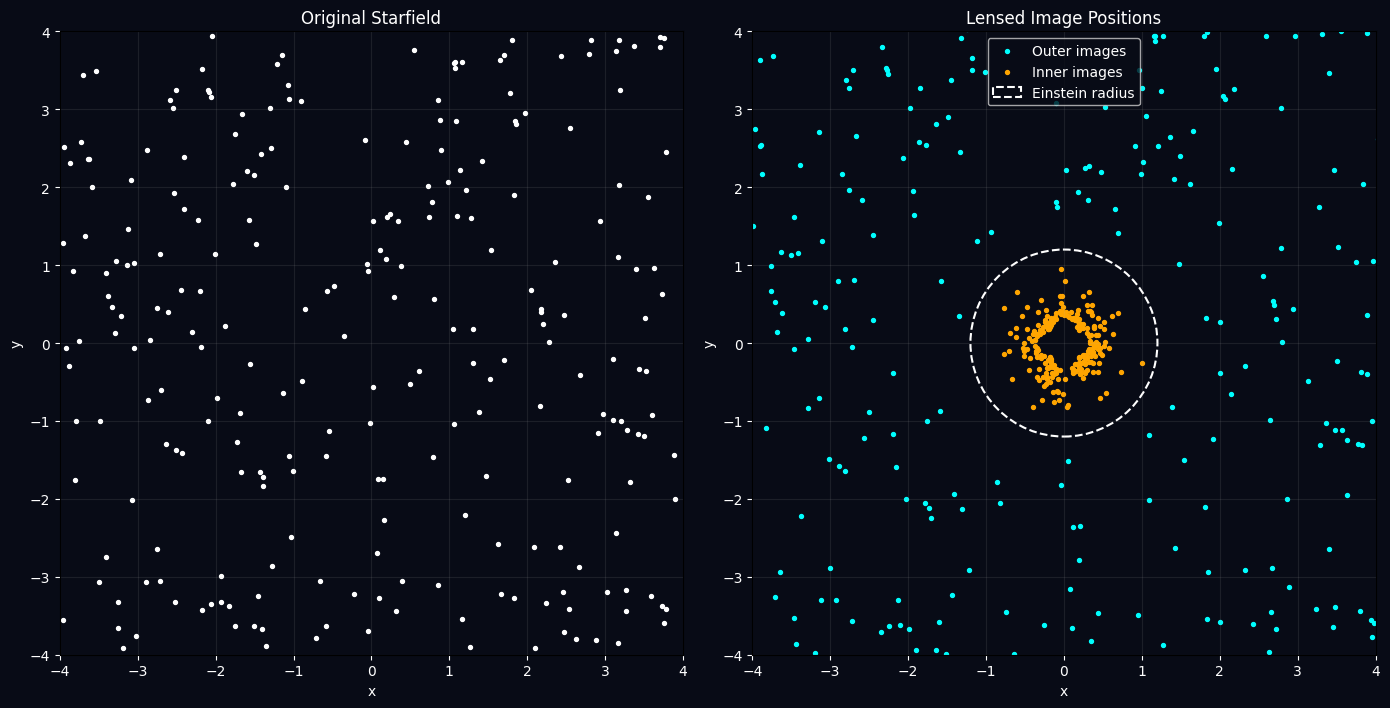

In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# # Original background stars
# axes[0].scatter(
#     beta_x,
#     beta_y,
#     s=8,
#     color="white"
# )

# axes[0].set_title("Original Starfield", color="white")

# # Lensed image positions
# axes[1].scatter(
#     theta_plus_x,
#     theta_plus_y,
#     s=8,
#     color="cyan",
#     label="Outer images"
# )

# axes[1].scatter(
#     theta_minus_x,
#     theta_minus_y,
#     s=8,
#     color="orange",
#     label="Inner images"
# )

# # Einstein ring reference
# axes[1].add_patch(
#     plt.Circle(
#         (0, 0),
#         theta_E,
#         fill=False,
#         linestyle="--",
#         linewidth=1.5,
#         color="white",
#         label="Einstein radius"
#     )
# )

# axes[1].set_title("Lensed Image Positions", color="white")
# axes[1].legend(facecolor="#080b16", labelcolor="white")

# for ax in axes:
#     ax.set_facecolor("#080b16")
#     ax.set_xlim(-4, 4)
#     ax.set_ylim(-4, 4)
#     ax.set_aspect("equal")
#     ax.set_xlabel("x", color="white")
#     ax.set_ylabel("y", color="white")
#     ax.tick_params(colors="white")
#     ax.grid(alpha=0.12)

# fig.patch.set_facecolor("#080b16")
# plt.tight_layout()
# plt.show()